In [1]:
import sys
sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/copersona/')
from copersona.utils import dmpax, tools
import pandas as pd
import numpy as np
from ortools.linear_solver import pywraplp
from sklearn.cluster import KMeans
import joblib

import findspark
findspark.init()
from pyspark.sql import SparkSession
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

spark = SparkSession \
    .builder \
    .appName('flowback_outcall_auuc') \
    .config("spark.yarn.queue", "root.profile_prod") \
    .config("spark.driver.memory", "50g") \
    .config("spark.driver.memoryOverhead", "4g") \
    .config("spark.executor.memory", "12g") \
    .config("spark.executor.memoryOverhead", "4g") \
    .config("spark.executor.cores", "4") \
    .config("spark.executor.instances", "8") \
    .config("spark.sql.shuffle.partitions", "400") \
    .config("spark.default.parallelism", "200") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.sql.adaptive.skewJoin.enabled", "true") \
    .config("spark.sql.autoBroadcastJoinThreshold", "104857600") \
    .config("spark.sql.broadcastTimeout", "600") \
    .config("spark.network.timeout", "600s") \
    .config("spark.executor.heartbeatInterval", "60s") \
    .config("mapred.input.dir.recursive", "TRUE") \
    .config("hive.mapred.supports.subdirectories", "TRUE") \
    .config("spark.sql.merge.mode", "FAST") \
    .config("spark.sql.merge.enabled", "TRUE") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.execution.arrow.maxRecordsPerBatch", "5000") \
    .config("spark.memory.fraction", "0.8") \
    .config("spark.memory.storageFraction", "0.3") \
    .enableHiveSupport() \
    .getOrCreate()


import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 加速 Spark DataFrame toPandas
spark.sql("set spark.sql.execution.arrow.enabled=true")

# 加载本地中文字体（你先上传一个 SimHei.ttf 到 home 目录）
font_path = "/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/jupyter/SimHei.ttf"  # 实际路径替换
font_prop = fm.FontProperties(fname=font_path)

# 设置全局字体为 SimHei
plt.rcParams['font.family'] = font_prop.get_name()
plt.rcParams['font.size'] = 13

# 可选：设置 serif 字体为 Times New Roman
plt.rcParams['font.serif'] = ['Times New Roman']

print("[Info] Spark Version : {}".format(spark.version))

Java HotSpot(TM) 64-Bit Server VM warning: Max heap size too large for Compressed Oops
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1774879587659_41050731, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1774879587659_41050731/


[Info] Spark Version : 3.2.0-101


In [2]:
import warnings
warnings.filterwarnings("ignore")

import pyspark
import os
import json
import math
import sys
import random
import importlib
import seaborn as sns
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


import pyspark.sql.types as T
from pyspark.files import SparkFiles
from pyspark.sql   import functions as func
from pyspark.sql   import DataFrame
from pyspark.sql.window import Window
from tqdm import tqdm
from functools import reduce



from ortools.linear_solver import pywraplp
from sklearn.metrics import roc_auc_score


sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/backflow/')

from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats   as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools
import datetime,json
import pandas as pd

from pyspark.sql.functions import col,desc, udf
from pyspark.sql.types import StructType
from pyspark.sql.types import StructField
from pyspark.sql.types import StringType
from pyspark.sql import DataFrame
from pyspark.sql import functions as func


importlib.reload(exp_setting)
importlib.reload(pgt)
importlib.reload(calib_metric)
importlib.reload(calib_stats)
importlib.reload(vis)
importlib.reload(pgtsimu)
importlib.reload(bkfl_tools)


pd.set_option('display.max_columns', None)

load metric func from causalml...
load metric func from causalml...


In [3]:
BASE_FMT_v1 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-11'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data.treatment as model_treatment,
        

        mapping_data.left65_minus_left63,
        mapping_data.left853_minus_left63,
        mapping_data.left63,


        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left65_minus_left63, 0.0)) as left65,
        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left853_minus_left63, 0.0)) as left853,
        
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3
    from base bs
    join (
       select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853_minus_left63,
            uplift_3 as left65_minus_left63,
            cost_1,
            cost_2,
            cost_3
        from growstrategy.ut_mkt_backflow_multi_treat_euen_v216_xnetwork12_new_uplift_epoch2_1_model_inference_di
        where label_dt between '2026-05-05' and '2026-05-10' 
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v1.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,model_treatment,left65_minus_left63,left853_minus_left63,left63,left65,left853,cost_1,cost_2,cost_3
0,迭代流量,探索,探索,留存6张3元,189092397057,v1_17592720651163,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,0.0,0.0,1,1.0,0.011915,0.008076,0.005694,0.017609,0.013770,0.009621,0.016640,0.019620
1,迭代流量,DS空白,DS空白,control_group,17595578191474,v1_82a7cd88f47fa76d86dc2d164301ec25,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-05-09,0.0,0.0,0,0.0,0.008938,0.006340,0.003312,0.012250,0.009652,0.005277,0.009467,0.013156
2,迭代流量,DS空白,DS空白,control_group,17592423925339,v1_17592599155760,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,47.0,2026-05-09,0.0,0.0,0,0.0,0.006137,0.004363,0.002507,0.008644,0.006871,0.001235,0.005082,0.006828
3,迭代流量,DS空白,DS空白,control_group,3081286325052,v1_17592639390415,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-09,0.0,0.0,0,0.0,0.016650,0.011256,0.009012,0.025661,0.020268,0.019364,0.027797,0.030961
4,迭代流量,DS空白,DS空白,control_group,17594641208932,v1_eaa9d5741ea915d4dd7a10b9db0ad6ba,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-09,0.0,0.0,0,0.0,0.013463,0.008933,0.006759,0.020222,0.015692,0.012242,0.021340,0.023625
5,迭代流量,探索,探索,8元留存5张3,3513157554118,v1_17592702238403,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,0.0,0.0,2,2.0,0.016372,0.009879,0.007079,0.023451,0.016958,0.008479,0.017694,0.021342
6,迭代流量,DS空白,DS空白,control_group,17592294073581,v1_17592639010840,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-09,0.0,0.0,0,0.0,0.031902,0.021166,0.014798,0.046700,0.035964,0.013810,0.041614,0.045945
7,迭代流量,探索,探索,留存6张3元,17594681488370,v1_59b9495d30e3faa96a5728d3fe5c3512,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,2026-05-09,0.0,0.0,1,1.0,0.005520,0.003348,0.001210,0.006730,0.004558,0.000296,0.003979,0.006536
8,迭代流量,探索,探索,留存6张5元,12133335,v1_17593120283145,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-09,0.0,0.0,3,3.0,0.022803,0.015038,0.011048,0.033851,0.026086,0.014394,0.033206,0.035977
9,迭代流量,探索,探索,8元留存5张3,17599966321136,v1_ef2479866639308f3512c348215c6408,2.0,1.0,0.021,0.0,1.0,0.12,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,1.0,0.0,2,2.0,0.036781,0.025994,0.019281,0.056062,0.045275,0.032316,0.064288,0.068497


In [3]:
BASE_FMT_v2 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-21'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        
        -- 1. 生成真实对照组标签
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data2.coupon_prob,
        
        -- 2. 解析预测打分
        mapping_data.left63,
        mapping_data.left853,
        mapping_data.left65,
        
        -- 3. 直接做差，生成排序依据
        case 
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        
        case 
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63
       
    from base bs
    left join (
       select 
            pid as oneid,         
            date_add(dt, 1) as join_dt,
            prediction[0] as left63,
            prediction[1] as left853,
            prediction[2] as left65
        from dm.ut_mkt_backflow_model_inference_di
        where dt between '2026-05-05' and '2026-05-20'
        and model = 'bkfl_multi_treatment_26_v2_uplift'
    ) mapping_data 
        on bs.oneid = mapping_data.oneid 
        and bs.dt = mapping_data.join_dt      
    left join (
        select 
            pid as oneid
            ,date_add(dt, 1) as dt
            ,weighted_prob as coupon_prob
        from dm.ut_mkt_backflow_model_inference_di
        where dt between '2026-05-05' and '2026-05-20'
        and model = 'bkfl_group_to_coupon_26_v2'
    ) mapping_data2 on bs.oneid = mapping_data2.oneid and bs.dt = mapping_data2.dt
)
select *
from prediction_agg
""").toPandas()
BASE_FMT_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,coupon_prob,left63,left853,left65,left65_minus_left63,left853_minus_left63
0,迭代流量,探索,探索,8元留存5张3,17592270785279,v1_0014f3f790998d0b9d5e5d4f7263c277,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-10,0.0,0.0,2,0.002440,0.012194,0.013740,0.015237,0.003043,0.001546
1,迭代流量,DS空白,DS空白,control_group,5000168831457,v1_001d8ca93f1a4b4c39d5935a029895d3,0.0,0.0,0.000,0.000,0.0,0.00,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-20,0.0,0.0,0,0.147725,0.040565,0.065798,0.073351,0.032785,0.025232
2,迭代流量,探索,探索,8元留存5张3,35185752341444,v1_002c388c1f4750f86a9e308b06ae54b1,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-20,0.0,0.0,2,0.006368,0.020607,0.033868,0.028098,0.007491,0.013261
3,迭代流量,探索,探索,留存6张5元,17595261398173,v1_003e77355a6ef1b4237852c1866c881e,2.0,1.0,0.021,0.000,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,2026-05-07,0.0,0.0,3,0.015807,0.005438,0.007257,0.006307,0.000869,0.001819
4,迭代流量,探索,探索,留存6张5元,2348196504611,v1_00bca6f5521f1f88da69e66dd12ed9a1,2.0,1.0,0.021,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-11,0.0,0.0,3,0.087591,0.018191,0.017318,0.020659,0.002468,-0.000873
5,迭代流量,DS空白,DS空白,control_group,17593622577690,v1_00c8b2f514181e555c186da6a3ef0b56,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-18,0.0,0.0,0,0.013832,0.026250,0.053069,0.052376,0.026125,0.026818
6,迭代流量,探索,探索,8元留存5张3,35184386542033,v1_00ea5318b8302eb5b7d6ac17b5c213b9,1.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-20,0.0,0.0,2,0.002851,0.009355,0.010342,0.012380,0.003025,0.000987
7,迭代流量,探索,探索,8元留存5张3,17593226862665,v1_00fa0923e257e06fc667f5a8f21a0dc8,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-17,0.0,0.0,2,0.005990,0.007864,0.013315,0.012080,0.004216,0.005451
8,迭代流量,DS空白,DS空白,control_group,17597294012611,v1_010bf5411ca22ffab5155b2ee88b8e5e,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-05-15,0.0,0.0,0,0.020593,0.003303,0.007297,0.010152,0.006849,0.003995
9,迭代流量,探索,探索,留存6张3元,17594930014647,v1_014df3e896929ac94318f1e83ac85f4f,2.0,1.0,0.000,0.021,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-10,0.0,0.0,1,0.003211,0.009013,0.018052,0.013628,0.004614,0.009039


In [4]:
BASE_FMT_v3 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-21'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data.treatment as model_treatment,
        
        mapping_data.left65_minus_left63,
        mapping_data.left65,
        mapping_data.left63,
        
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3
    from base bs
    join (
       select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left65_minus_left63,
            uplift_3 as left65,
            cost_1,
            cost_2,
            cost_3
        from dm.ut_alg_flowback_app_package_euen_26_v123_month_3_4_model_inference_di
        where label_dt between '2026-05-05' and '2026-05-20' 
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v3.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,model_treatment,left65_minus_left63,left65,left63,cost_1,cost_2,cost_3
0,迭代流量,探索,探索,留存6张3元,100178357,v1_17592930716160,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,0.0,0.0,1,1.0,0.002311,0.010543,0.008232,0.009199,0.028322,0.014434
1,迭代流量,DS空白,DS空白,control_group,100181538,v1_17592916201535,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-14,0.0,0.0,0,0.0,-0.000439,0.005067,0.005506,0.006399,0.018662,0.006875
2,迭代流量,探索,探索,留存6张3元,1002395537409,v1_d1c55e6e467557d482534f46d84d3edf,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-08,0.0,0.0,1,1.0,0.002296,0.011070,0.008774,0.018535,0.045003,0.027271
3,迭代流量,DS空白,DS空白,control_group,100386113,v1_17593018318642,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,2026-05-20,0.0,0.0,0,0.0,0.001782,0.009130,0.007349,0.008760,0.023818,0.010348
4,迭代流量,探索,探索,8元留存5张3,100515123200,v1_17592718328497,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-14,0.0,0.0,2,2.0,0.015496,0.031916,0.016420,0.026917,0.070762,0.052367
5,迭代流量,DS空白,DS空白,control_group,1005404295171,v1_17592729019697,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-19,0.0,0.0,0,0.0,0.005420,0.015153,0.009733,0.017957,0.043640,0.025429
6,迭代流量,探索,探索,8元留存5张3,100715548,v1_1bad91f7e0caf789293505b3e100b36a,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-09,0.0,0.0,2,2.0,0.016612,0.033755,0.017143,0.034083,0.086961,0.058437
7,迭代流量,DS空白,DS空白,control_group,100826357762,v1_17592720927599,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,2026-05-06,0.0,0.0,0,0.0,0.001587,0.008217,0.006630,0.005813,0.017001,0.007915
8,迭代流量,DS空白,DS空白,control_group,100840611,v1_17592916244418,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,2026-05-11,0.0,0.0,0,0.0,-0.000608,0.004181,0.004788,0.004812,0.011027,0.003245
9,迭代流量,探索,探索,留存6张3元,1010352914433,v1_17592756525451,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,2026-05-19,0.0,0.0,1,1.0,0.002154,0.010801,0.008648,0.009501,0.028080,0.014125


In [6]:
BASE_FMT_v4 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-26' and '2026-06-09'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        
        -- 1. 生成真实对照组标签
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment     
        ,nvl(mapping_data.left63, 999) as left63
        ,nvl(mapping_data.left853, 999) as left853
        ,nvl(mapping_data.left65, 999) as left65
        ,nvl(mapping_data.left1053, 999) as left1053
        ,nvl(mapping_data2.coupon_prob, 999) as coupon_prob,
        case
            when nvl(left853, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left853 - left63
        end as left853_minus_left63,
        --Note:在这添加其余所需的T与left63的打分!!!
        case
            when nvl(left65, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left65 - left63
        end as left65_minus_left63,
        case
            when nvl(left65, 999) = 999 or nvl(left853, 999) = 999 then 999
            else left65 - left853
        end as left65_minus_left853,
        case
            when nvl(left1053, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left1053 - left63
        end as left1053_minus_left63,
        case
            when nvl(left1053, 999) = 999 or nvl(left853, 999) = 999 then 999
            else left1053 - left853
        end as left1053_minus_left853,
        case
            when nvl(left1053, 999) = 999 or nvl(left65, 999) = 999 then 999
            else left1053 - left65
        end as left1053_minus_left65
    from base bs
    left join (
       select 
            pid as oneid      
            ,date_add(dt, 1) as join_dt
            ,prediction[0] as left63
            ,prediction[1] as left853
            ,prediction[2] as left65
            ,prediction[3] as left1053
        from dm.ut_mkt_backflow_model_inference_di
        where 
            dt between '2026-05-25' and '2026-06-08'
            and model = 'bkfl_multi_treatment_26_v2_5m_uplift' --26年因果森林v25月份数据
    ) mapping_data 
        on bs.oneid = mapping_data.oneid 
        and bs.dt = mapping_data.join_dt      
    left join (
        select 
            pid as oneid
            ,date_add(dt, 1) as dt
            ,weighted_prob as coupon_prob
        from dm.ut_mkt_backflow_model_inference_di
        where 
            dt between '2026-05-25' and '2026-06-08'
            and model = 'bkfl_group_to_coupon_26_v2_5m' --26v2年成本预估xgb-5月份数据
    ) mapping_data2 on bs.oneid = mapping_data2.oneid and bs.dt = mapping_data2.dt
)
select *
from prediction_agg
""").toPandas()
BASE_FMT_v4.head(5)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,left63,left853,left65,left1053,coupon_prob,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65
0,迭代流量,探索,探索,留存6张3元,17593513424773,v1_00042b67df9c6db575958f88f592ef07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-06-08,0.0,0.0,1,0.011321,0.014621,0.018179,0.018227,0.002148,0.003300,0.006858,0.003558,0.006905,0.003606,0.000047
1,迭代流量,DS空白,DS空白,control_group,70368804168227,v1_001a886eccda251f987cb35e91ec62e0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-06-08,0.0,0.0,0,0.015652,0.022918,0.025550,0.032879,0.006022,0.007266,0.009897,0.002632,0.017227,0.009961,0.007329
2,迭代流量,DS空白,DS空白,control_group,17600293222031,v1_004d970bac42bb77d26c5bcf9f51be44,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-06-07,0.0,0.0,0,0.029405,0.044489,0.057289,0.056227,0.044103,0.015085,0.027884,0.012799,0.026822,0.011737,-0.001062
3,迭代流量,DS空白,DS空白,control_group,17594671713271,v1_0052bac56ff1c289b8532ae26f532d51,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,2026-05-30,0.0,0.0,0,0.002977,0.004038,0.006662,0.012223,0.000435,0.001061,0.003686,0.002625,0.009247,0.008186,0.005561
4,迭代流量,DS空白,DS空白,control_group,17594698385380,v1_006dbd4b6b4735aec00a01a4625c60e6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,2026-05-27,0.0,0.0,0,0.002985,0.004108,0.007795,0.010830,0.000681,0.001123,0.004810,0.003687,0.007846,0.006723,0.003035


left1053    0.777119
Random      0.499598
dtype: float64
****************************************


[left1053    0.777119
 Random      0.499598
 dtype: float64]

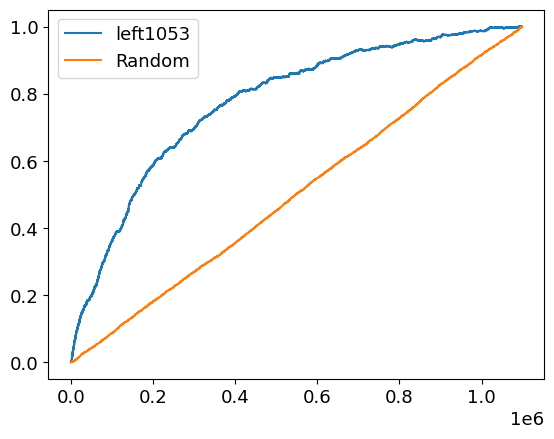

In [7]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[4], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left1053'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left63    0.862854
Random    0.498244
dtype: float64
****************************************


[left63    0.862854
 Random    0.498244
 dtype: float64]

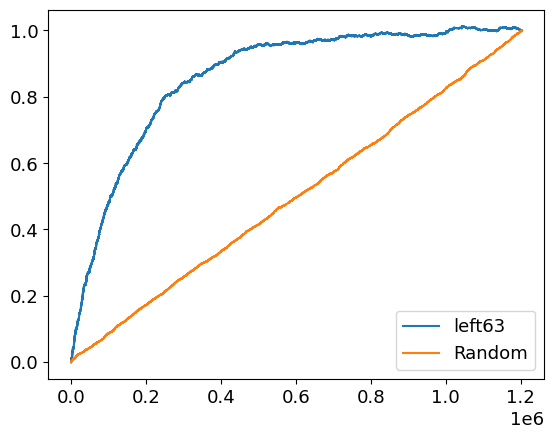

In [8]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left65_minus_left63    0.806881
Random                 0.509144
dtype: float64
****************************************


[left65_minus_left63    0.806881
 Random                 0.509144
 dtype: float64]

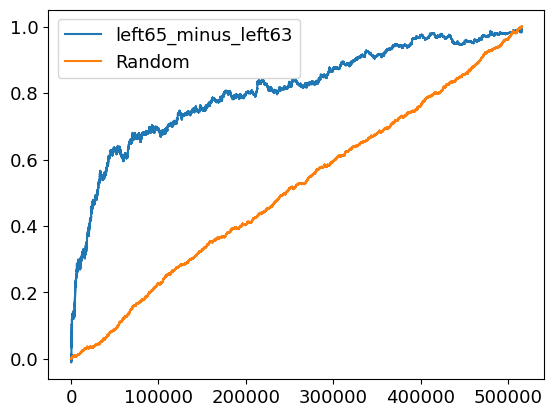

In [6]:
vis.draw_auuc(BASE_FMT_v3,
              treatments=[3], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=1, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left65    0.803463
Random    0.500326
dtype: float64
****************************************


[left65    0.803463
 Random    0.500326
 dtype: float64]

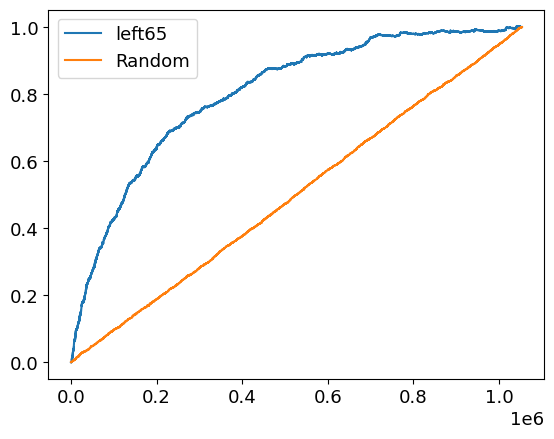

In [9]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[3], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left853    0.832049
Random     0.501493
dtype: float64
****************************************


[left853    0.832049
 Random     0.501493
 dtype: float64]

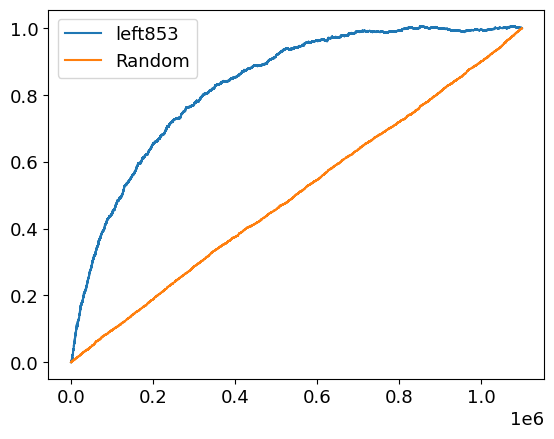

In [10]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[2], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left853'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left63    0.837774
Random    0.501453
dtype: float64
****************************************


[left63    0.837774
 Random    0.501453
 dtype: float64]

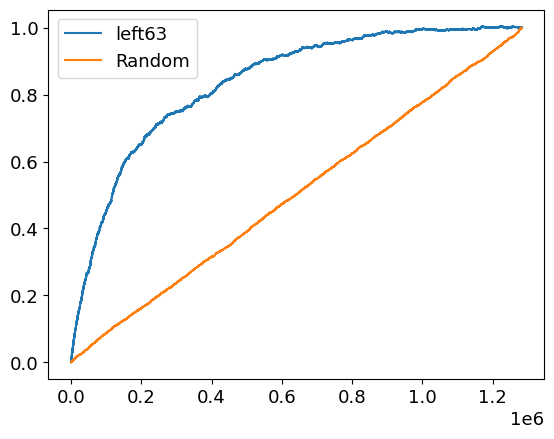

In [9]:
vis.draw_auuc(BASE_FMT_v2,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left65_minus_left63    0.679919
Random                 0.499181
dtype: float64
****************************************


[left65_minus_left63    0.679919
 Random                 0.499181
 dtype: float64]

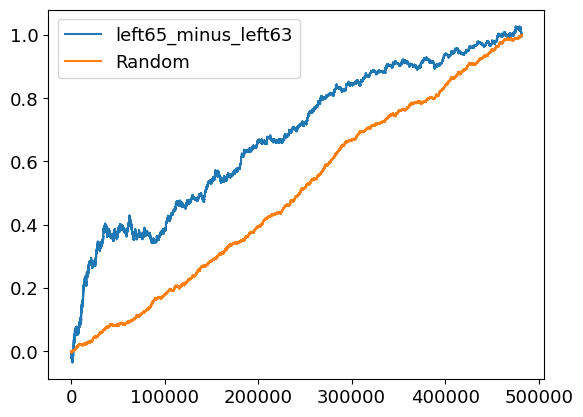

In [12]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[3], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=1, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left853_minus_left63    0.577280
Random                  0.518877
dtype: float64
****************************************


[left853_minus_left63    0.577280
 Random                  0.518877
 dtype: float64]

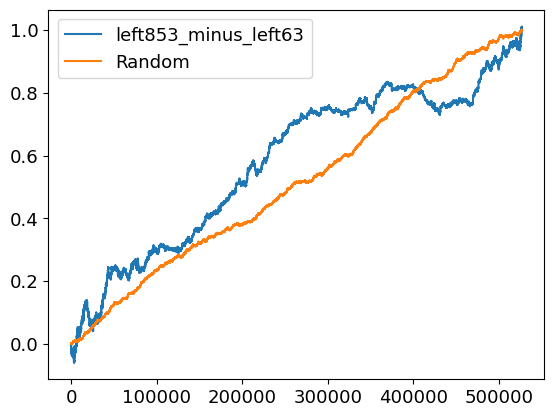

In [13]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[2], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left853_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=1, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left1053_minus_left63    0.620769
Random                   0.495165
dtype: float64
****************************************


[left1053_minus_left63    0.620769
 Random                   0.495165
 dtype: float64]

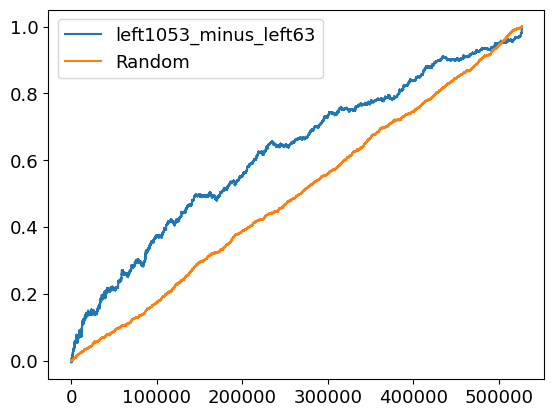

In [14]:
vis.draw_auuc(BASE_FMT_v4,
              treatments=[4], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left1053_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=1, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [11]:
spark.stop()